# 01 - Exploratory analysis of the Bias in Bios dataset

The dataset of De-Arteaga et al. (2019) holds short professional biographies
with an occupation and a gender label. This notebook describes it, fixes which
occupations and which biographies the thesis keeps, and writes the cleaned
dataset that the rest of the series builds on.

- **Question:** What does the dataset hold, and which part of it can carry the
  two studies?
- **Expectation:** none directional; the notebook is descriptive.
- **Status:** first step of the series. The decisions of section 7 are the ones
  the later notebooks follow.
- **Unit and test:** biography; counts, shares and distributions, no inference.
- **Inputs:** the three published parquet files (train, dev, test) of
  `hf://datasets/LabHC/bias_in_bios`, merged into one frame, because the
  question is about language and not about a classifier.
- **Outputs:** `outputs/df_clean.parquet`, and under `outputs/figures/` the
  figures `fig_gender_distribution.png`, `fig_occupation_distribution.png`,
  `fig_gender_per_occupation.png`, `fig_text_length.png`,
  `fig_textlength_boxplot.png`, `fig_wordcount_per_occ.png` and
  `fig_wordcount_gap_quantiles.png`.
- **Run:** from a fresh kernel, top to bottom, from the folder `notebooks/`;
  the paths are relative to it. The dataset is read over the network.
- **Decisions:** biographies with an identical text are dropped, the occupation
  `rapper` is dropped because it holds almost no women, and an occupation
  counts as carrying its own estimate from 200 biographies per gender upwards.

Sections: (1) data structure, (2) gender, (3) occupation, (4) biography texts,
(5) gender markers, (6) quality checks, (7) pipeline decisions, (8) the share
of women against the BLS.


In [2]:
import os, pathlib, sys

# -- Working directory -> project root ---------------------------------------

# The notebook may be opened from notebooks/, from the project root or from a
# copy in notebooks/archive/. The root is the nearest folder upwards that holds
# both outputs/ and src/, so every path below can be written relative to it.
ROOT = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
             if (p / 'outputs').is_dir() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise RuntimeError('project root not found: no folder at or above the '
                       'working directory holds both outputs/ and src/')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print(f'working directory: {ROOT.name}')

working directory: Thesis_Model


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re
from collections import Counter

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
pd.set_option('display.max_colwidth', 120)

OCCUPATION_MAP = {
    0: 'accountant',        1: 'architect',       2: 'attorney',        3: 'chiropractor',
    4: 'comedian',          5: 'composer',         6: 'dentist',         7: 'dietitian',
    8: 'dj',                9: 'filmmaker',       10: 'interior_designer', 11: 'journalist',
    12: 'model',           13: 'nurse',           14: 'painter',        15: 'paralegal',
    16: 'pastor',          17: 'personal_trainer', 18: 'photographer',   19: 'physician',
    20: 'poet',            21: 'professor',       22: 'psychologist',   23: 'rapper',
    24: 'software_engineer', 25: 'surgeon',       26: 'teacher',        27: 'yoga_teacher'
}
GENDER_MAP    = {0: 'Male', 1: 'Female'}
GENDER_COLORS = {'Male': '#4878D0', 'Female': '#EE854A'}

# De-Arteaga et al. published three parquet files (train/dev/test) for their classifier.
# I merge all into one df - I analyse language, not train a model.
parquet_files = [
    'data/train-00000-of-00001-0ab65b32c47407e8.parquet',
    'data/test-00000-of-00001-5598c840ce8de1ee.parquet',
    'data/dev-00000-of-00001-e6551072fff26949.parquet'
]

df = pd.concat(
    [pd.read_parquet(f'hf://datasets/LabHC/bias_in_bios/{f}') for f in parquet_files],
    ignore_index=True
)

df['occupation']   = df['profession'].map(OCCUPATION_MAP)
df['gender_label'] = df['gender'].map(GENDER_MAP)
df['word_count']   = df['hard_text'].str.split().str.len()

print(f'Total bios: {len(df):,}')
print(df['gender_label'].value_counts())

Total bios: 396,189
gender_label
Male      213543
Female    182646
Name: count, dtype: int64


---
## 1. Data Structure

In [4]:
print('=== Features ===')
print(df.dtypes)
print()
print(f'Total bios: {len(df):,}')

=== Features ===
hard_text       object
profession       int64
gender           int64
occupation      object
gender_label    object
word_count       int64
dtype: object

Total bios: 396,189


In [5]:
print('=== 5 Example Bios (read manually) ===')
for i, row in df.sample(5, random_state=42).iterrows():
    print(f'\n[{i}]  Occupation: {row["occupation"]}  |  Gender: {row["gender_label"]}  |  Words: {row["word_count"]}')
    print(row['hard_text'])

=== 5 Example Bios (read manually) ===

[204648]  Occupation: dentist  |  Gender: Male  |  Words: 30
He practices in Abilene, Texas and has the professional credentials of DMD. The NPI Number for Dr. Dennis Edward Stelton is 1285848747 and he holds a Licence No. 17520 (Texas).

[214358]  Occupation: physician  |  Gender: Female  |  Words: 24
Prior to joining Skin Solutions Dermatology, Hannah was part of a well-known cosmetic dermatology practice in Arizona where she rigorously trained in this high...

[146258]  Occupation: professor  |  Gender: Female  |  Words: 32
She is the author of two poetry collections, "What to Eat, What to Drink, What to Leave for Poison" and "Suck on the Marrow," and has helped edit two other poetry anthologies.

[309728]  Occupation: professor  |  Gender: Female  |  Words: 85
As the faculty advisor for the Vanderbilt student chapter of the American Society of Civil Engineers, she and the chapter have received national recognition several times for their outs

**Interpretation:** The dataset has three fields: `hard_text` (biography), `profession` (numeric 0-27), `gender` (0=Male, 1=Female). The example bios show typical **third-person narratives** - often Wikipedia-style, short and factual. This is a known limitation: hedging, direct self-attribution, and first-person framing are structurally unmeasurable here. Document transparently in thesis.

---
## 2. Gender Variable

In [6]:
print('=== Gender Encoding ===')
print('Unique values:', sorted(df['gender'].unique()), '  → 0=Male, 1=Female (inferred from pronouns)')
print()
print('=== Distribution (full dataset) ===')
c = df['gender_label'].value_counts()
p = df['gender_label'].value_counts(normalize=True) * 100
print(f'  Male:   {c["Male"]:>6,} ({p["Male"]:.1f}%)')
print(f'  Female: {c["Female"]:>6,} ({p["Female"]:.1f}%)')
print()
print('=== NaN / Outliers ===')
print(f'  Missing values in gender: {df["gender"].isna().sum()}')
print(f'  Values outside {{0,1}}:     {(~df["gender"].isin([0,1])).sum()}')

=== Gender Encoding ===
Unique values: [np.int64(0), np.int64(1)]   → 0=Male, 1=Female (inferred from pronouns)

=== Distribution (full dataset) ===
  Male:   213,543 (53.9%)
  Female: 182,646 (46.1%)

=== NaN / Outliers ===


  Missing values in gender: 0
  Values outside {0,1}:     0


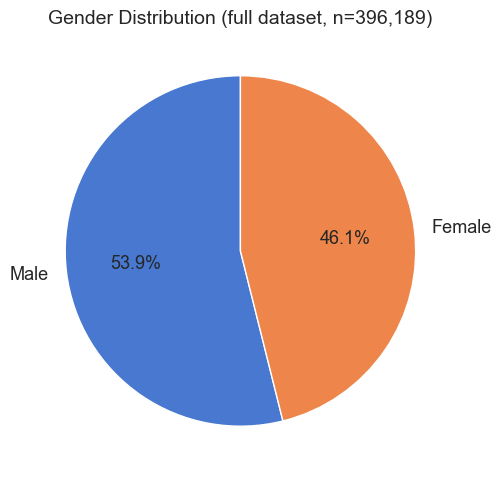

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
counts = df['gender_label'].value_counts()
ax.pie(counts, labels=counts.index, autopct='%1.1f%%',
       colors=[GENDER_COLORS['Male'], GENDER_COLORS['Female']],
       startangle=90, textprops={'fontsize': 13})
ax.set_title(f'Gender Distribution (full dataset, n={len(df):,})', fontsize=14)
plt.tight_layout()
plt.savefig('outputs/figures/fig_gender_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** Gender is binary and cleanly coded - no NaNs, no outliers. The dataset has a moderate male majority: **53.9% Male (213,543) vs. 46.1% Female (182,646)** out of 396,189 total bios. This is less skewed than the train split alone suggested (~54% vs ~46%), but still reflects the source bias of the web crawl: women are somewhat underrepresented in publicly visible professional biographies (Wikipedia, company websites). For Study 1: OLS with occupation fixed effects controls for the fact that certain female-dominated occupations are smaller.

---
## 3. Occupation Variable

In [8]:
print(f'Occupation categories: {df["occupation"].nunique()}')
print()
print('Distribution (full dataset):')
print(df['occupation'].value_counts().to_string())

Occupation categories: 28

Distribution (full dataset):
occupation
professor            118076
physician             40998
attorney              32570
photographer          24269
journalist            19941
nurse                 18950
psychologist          18380
teacher               16203
dentist               14585
surgeon               13587
architect             10108
painter                7734
model                  7491
poet                   7014
filmmaker              6996
software_engineer      6912
accountant             5633
composer               5599
dietitian              3952
comedian               2809
chiropractor           2655
pastor                 2523
paralegal              1765
yoga_teacher           1659
dj                     1486
interior_designer      1461
personal_trainer       1430
rapper                 1403


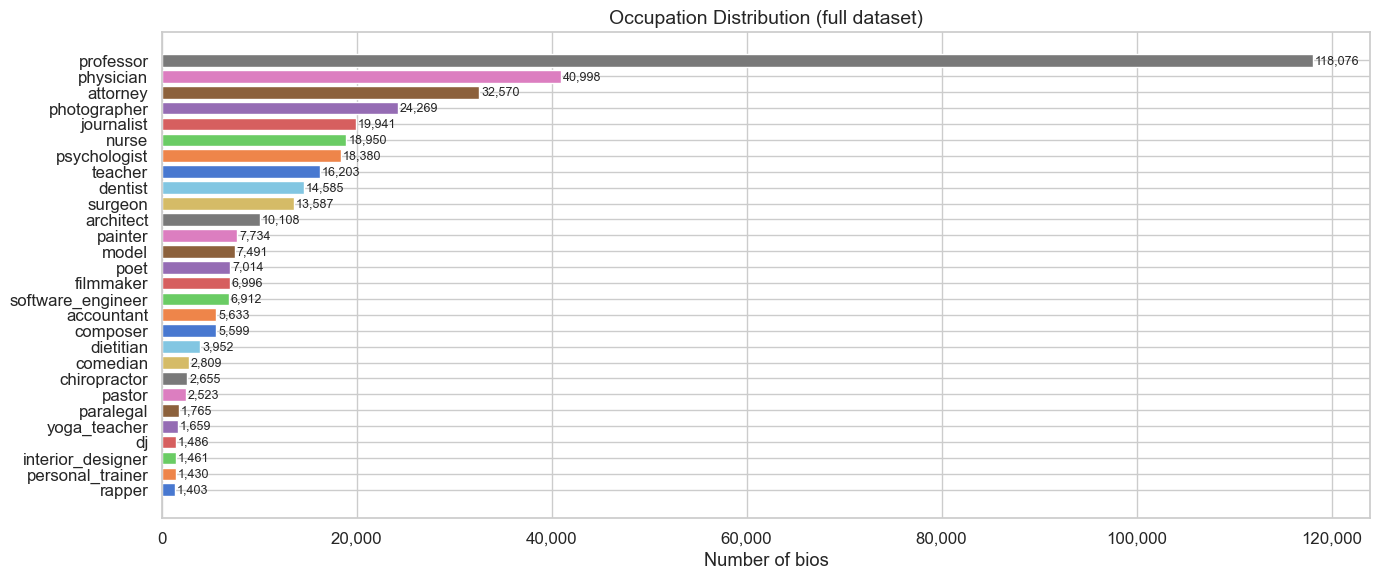

In [9]:
fig, ax = plt.subplots(figsize=(14, 6))
occ_sorted = df['occupation'].value_counts().sort_values()
bars = ax.barh(occ_sorted.index, occ_sorted.values,
               color=sns.color_palette('muted', len(occ_sorted)), edgecolor='white')
ax.set_xlabel('Number of bios')
ax.set_title('Occupation Distribution (full dataset)', fontsize=14)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar, val in zip(bars, occ_sorted.values):
    ax.text(val + 200, bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('outputs/figures/fig_occupation_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
occ_gender = (df.groupby(['occupation', 'gender_label'])
              .size().unstack(fill_value=0))
occ_gender['Female_%'] = (occ_gender['Female'] /
                          (occ_gender['Female'] + occ_gender['Male']) * 100).round(1)
occ_gender['Total'] = occ_gender['Female'] + occ_gender['Male']
occ_gender = occ_gender.sort_values('Female_%', ascending=False)
print('Gender balance per occupation (sorted by female share):')
print(occ_gender[['Female', 'Male', 'Total', 'Female_%']].to_string())

Gender balance per occupation (sorted by female share):
gender_label       Female   Male   Total  Female_%
occupation                                        
dietitian            3669    283    3952      92.8
nurse               17215   1735   18950      90.8
paralegal            1498    267    1765      84.9
yoga_teacher         1402    257    1659      84.5
model                6197   1294    7491      82.7
interior_designer    1180    281    1461      80.8
psychologist        11409   6971   18380      62.1
teacher              9759   6444   16203      60.2
journalist           9871  10070   19941      49.5
physician           20240  20758   40998      49.4
poet                 3439   3575    7014      49.0
painter              3537   4197    7734      45.7
personal_trainer      652    778    1430      45.6
professor           53259  64817  118076      45.1
attorney            12471  20099   32570      38.3
accountant           2067   3566    5633      36.7
photographer         8666 

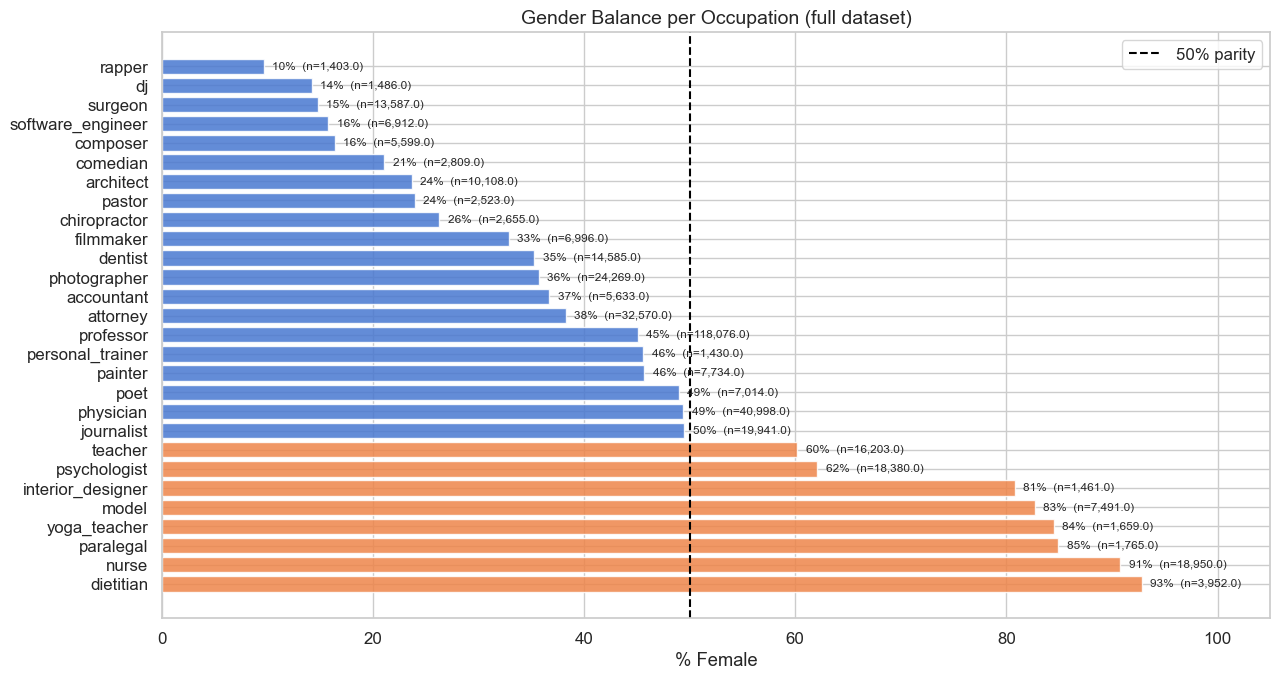

In [11]:
fig, ax = plt.subplots(figsize=(13, 7))
colors = [GENDER_COLORS['Female'] if p > 50 else GENDER_COLORS['Male']
          for p in occ_gender['Female_%']]
bars = ax.barh(occ_gender.index, occ_gender['Female_%'],
               color=colors, alpha=0.85, edgecolor='white')
ax.axvline(50, color='black', linestyle='--', linewidth=1.5, label='50% parity')
ax.set_xlim(0, 105)
ax.set_xlabel('% Female')
ax.set_title('Gender Balance per Occupation (full dataset)', fontsize=14)
ax.legend()
for bar, (_, row) in zip(bars, occ_gender.iterrows()):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
            f'{row["Female_%"]:.0f}%  (n={row["Total"]:,})', va='center', fontsize=8.5)
plt.tight_layout()
plt.savefig('outputs/figures/fig_gender_per_occupation.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** The 28 occupations are **massively imbalanced** (professor 118K vs. rapper 1,403 - factor ~84). More importantly: strong **occupational gender segregation** - dietitian (92.8% F), nurse (90.8% F), paralegal (84.9% F), yoga_teacher (84.5% F) are female-dominated; rapper (90.3% M), dj (85.8% M), surgeon (85.2% M), software_engineer (84.2% M) are male-dominated. Journalist and physician are near parity (~49-50% F). This is not a data error - it reflects real-world societal segregation and is a key descriptive finding for the thesis. OLS therefore requires occupation fixed effects - otherwise you measure occupation-gender correlation rather than genuine language differences.

---
## 4. Bio Text Analysis

In [12]:
print('=== Text Length (words) — overall ===')
print(df['word_count'].describe().round(1))
print()
print('=== Text Length by Gender ===')
print(df.groupby('gender_label')['word_count'].describe().round(1))

=== Text Length (words) — overall ===
count    396189.0
mean         60.7
std          28.4
min           7.0
25%          37.0
50%          55.0
75%          79.0
max         179.0
Name: word_count, dtype: float64

=== Text Length by Gender ===
                 count  mean   std  min   25%   50%   75%    max
gender_label                                                    
Female        182646.0  60.0  28.3  7.0  36.0  55.0  78.0  175.0
Male          213543.0  61.3  28.6  8.0  38.0  56.0  80.0  179.0


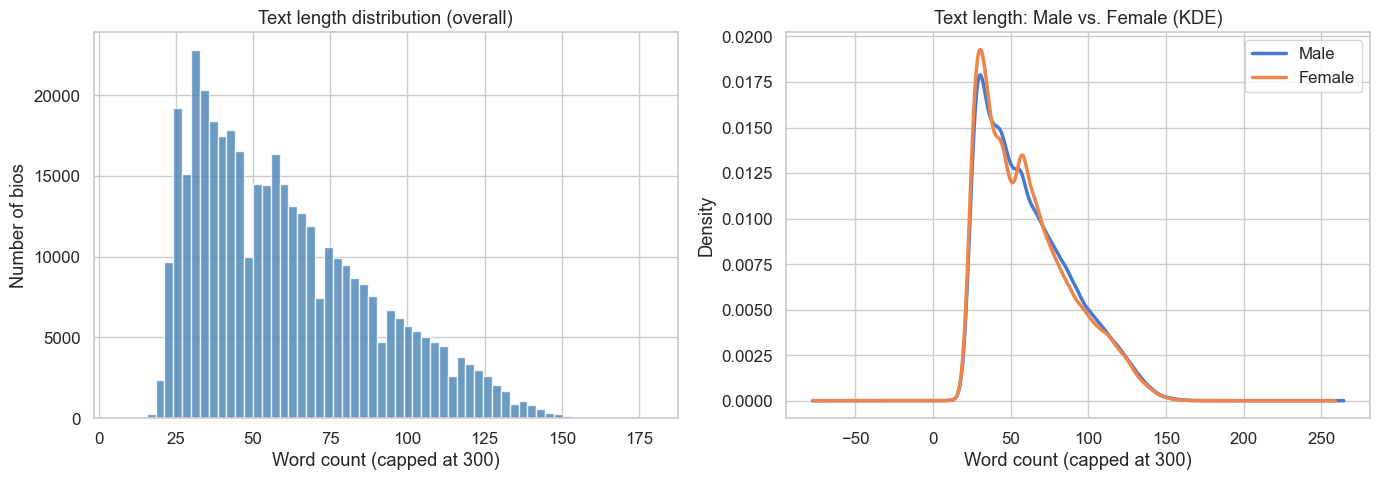

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['word_count'].clip(upper=300), bins=60,
             color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_xlabel('Word count (capped at 300)')
axes[0].set_ylabel('Number of bios')
axes[0].set_title('Text length distribution (overall)')

for gender, color in GENDER_COLORS.items():
    subset = df[df['gender_label'] == gender]['word_count'].clip(upper=300)
    subset.plot.kde(ax=axes[1], label=gender, color=color, linewidth=2.5)
axes[1].set_xlabel('Word count (capped at 300)')
axes[1].set_title('Text length: Male vs. Female (KDE)')
axes[1].legend()

plt.tight_layout()
plt.savefig('outputs/figures/fig_text_length.png', dpi=150, bbox_inches='tight')
plt.show()

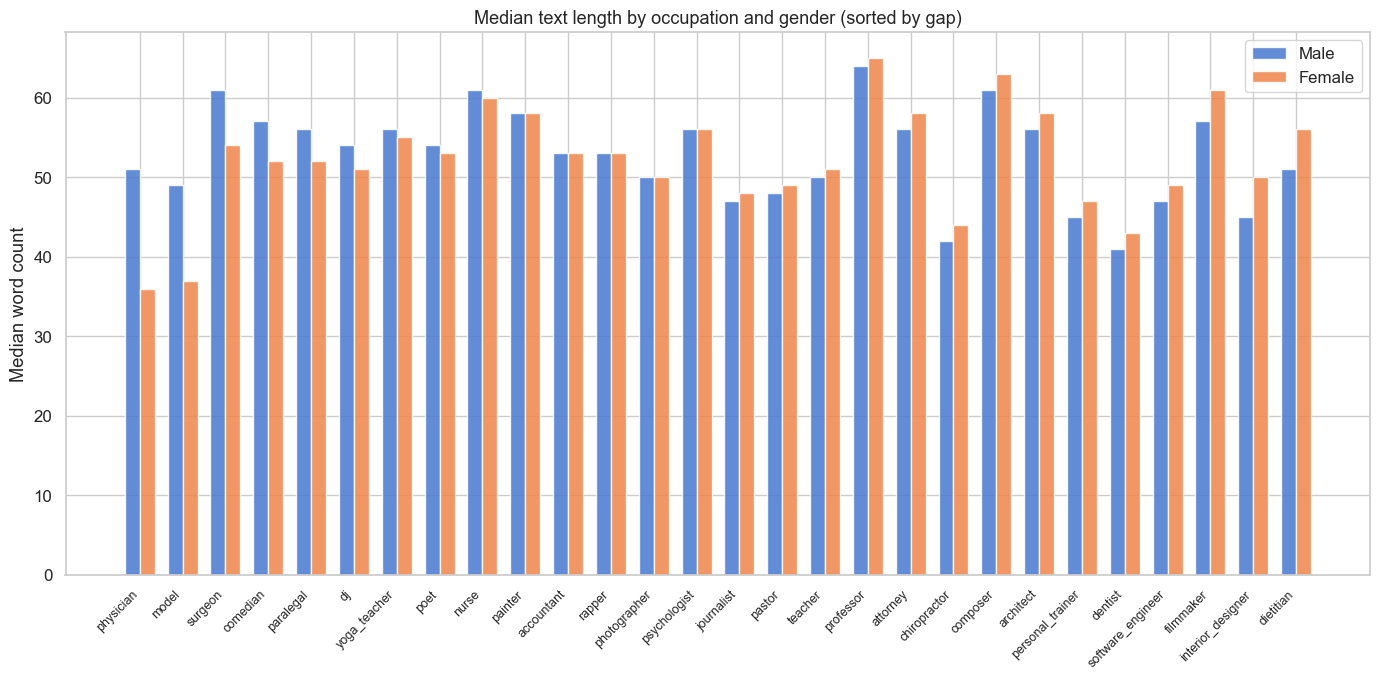

Top 10 Male-Female gap (median words):
occupation
physician       15.0
model           12.0
surgeon          7.0
comedian         5.0
paralegal        4.0
dj               3.0
yoga_teacher     1.0
poet             1.0
nurse            1.0
painter          0.0
Name: gap_M_minus_F, dtype: float64


In [14]:
occ_wc = (df.groupby(['occupation', 'gender_label'])['word_count']
          .median().unstack())
occ_wc['gap_M_minus_F'] = occ_wc['Male'] - occ_wc['Female']
occ_wc = occ_wc.sort_values('gap_M_minus_F', ascending=False)

fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(occ_wc))
w = 0.35
ax.bar(x - w/2, occ_wc['Male'],   w, label='Male',   color=GENDER_COLORS['Male'],   alpha=0.85)
ax.bar(x + w/2, occ_wc['Female'], w, label='Female', color=GENDER_COLORS['Female'], alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(occ_wc.index, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Median word count')
ax.set_title('Median text length by occupation and gender (sorted by gap)', fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig('outputs/figures/fig_wordcount_per_occ.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 10 Male-Female gap (median words):')
print(occ_wc['gap_M_minus_F'].head(10).round(1))

In [15]:
print('=== 20 Sample Bios (stratified by occupation and gender) ===')
for occ in ['professor', 'nurse', 'software_engineer', 'attorney', 'journalist']:
    for gender in ['Male', 'Female']:
        row = (df[(df['occupation'] == occ) & (df['gender_label'] == gender)]
               .sample(1, random_state=42).iloc[0])
        print(f'\n[{occ.upper()} | {gender} | {row["word_count"]} words]')
        print(row['hard_text'])

=== 20 Sample Bios (stratified by occupation and gender) ===

[PROFESSOR | Male | 81 words]
He received his Ph.D. in Computer Science from VirginiaTech under the supervision of Dr. Eli Tilevich in 2014. His research interests span Mobile Computing, Cloud-Based Systems, and Software Engineering, as applied to Middleware, Energy Efficiency, and Software Refactoring. Prior to his doctoral studies, he earned B.S. from Kyungpook National University and M.S. from Gwangju Institute of Science and Technology (GIST), South Korea in 2003 and 2005 respectively. He also held senior software engineering positions at Daewoo Electronics and NHN (now Naver).

[PROFESSOR | Female | 54 words]
She is the vice chair of the Georgia Commission on Family Violence, a board member of the Women's Resource Center to End Domestic Violence, associate director for education at Emory's Center for Injury Control, a member of the Center for Women Advisory Council, and co-chair of the Intimate Partner Violence Working 

In [16]:
df['non_ascii_ratio'] = df['hard_text'].apply(
    lambda t: sum(1 for c in t if ord(c) > 127) / max(len(t), 1)
)
suspicious = df[df['non_ascii_ratio'] > 0.05]
print(f'Bios with >5% non-ASCII characters: {len(suspicious)} ({len(suspicious)/len(df)*100:.2f}%)')
if len(suspicious) > 0:
    for _, row in suspicious.head(3).iterrows():
        print(f'  [{row["occupation"]}]  {row["hard_text"][:150]}')

Bios with >5% non-ASCII characters: 126 (0.03%)
  [photographer]  Self-taught as a photographer, Westra has an explicit interest in Maori culture, exemplified by her controversial children’s book, Washday at the Pa, 
  [composer]  He has toured the world with acts such as Stellastarr , The Killers, Jane's Addicition and. Пикник - Азбука Морзе Вступление: Am Em Am Em Am Чтобы вре
  [professor]  Coming from a philological background, he did his research as a Fulbright grantee at SUNY at Buffalo, and received a PhD in American literature in 200


=== Word count quantiles by gender ===
gender_label  Female   Male  gap_M_minus_F
p10             28.0   29.0            1.0
p25             36.0   38.0            2.0
p50             55.0   56.0            1.0
p75             78.0   80.0            2.0
p90            103.0  104.0            1.0
p95            116.0  117.0            1.0

Mean  — Male: 61.3  Female: 60.0  gap: 1.2


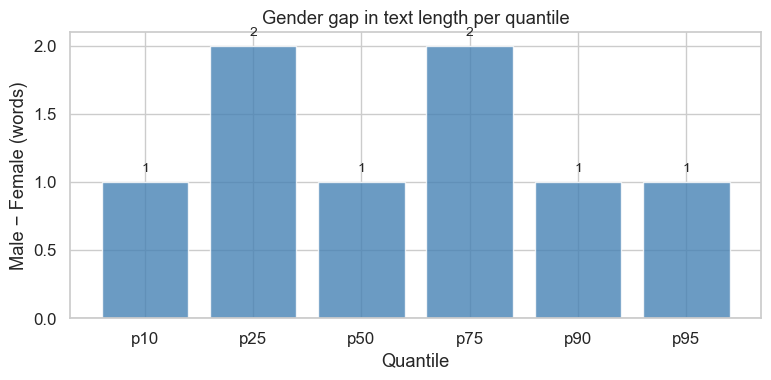

In [17]:
print('=== Word count quantiles by gender ===')
quantiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
qdf = (df.groupby('gender_label')['word_count']
       .quantile(quantiles).unstack(level=0))
qdf.index = [f'p{int(q*100)}' for q in quantiles]
qdf['gap_M_minus_F'] = (qdf['Male'] - qdf['Female']).round(1)
mean_m = df[df['gender_label'] == 'Male']['word_count'].mean()
mean_f = df[df['gender_label'] == 'Female']['word_count'].mean()
print(qdf.round(1).to_string())
print(f'\nMean  — Male: {mean_m:.1f}  Female: {mean_f:.1f}  gap: {mean_m - mean_f:.1f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(qdf.index, qdf['gap_M_minus_F'], color='steelblue', alpha=0.8, edgecolor='white')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Quantile')
ax.set_ylabel('Male − Female (words)')
ax.set_title('Gender gap in text length per quantile')
for i, (_, val) in enumerate(qdf['gap_M_minus_F'].items()):
    ax.text(i, val + 0.05, f'{val:.0f}', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('outputs/figures/fig_wordcount_gap_quantiles.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** Text lengths are **remarkably compact** - median 55 words, mean ~61, max 179. No bio exceeds 179 words; IQR is 37-79.

The gender gap is **small and structurally flat**: Male has a +1 to +2 word advantage at every quantile from p10 to p95 (mean gap: 1.3 words). Critically, the gap does *not* grow in the upper tail - p90 gap is just 1 word, same as the median. This has two methodological implications:

- The gap is **proportional**, so `log(word_count)` as a single control variable is sufficient - no interaction terms or quantile-specific controls needed.
- Any gender difference in feature frequencies (agentic verbs, passive constructions) cannot be explained by a few unusually long male bios; a flat gap points to a systemic pattern distributed across the full length range.

Almost all bios are in English - spaCy `en_core_web_lg` applies safely.

---
## 5. Gender Markers

In [18]:
ANY_MARKER = re.compile(r'\b(?:he|she|his|her|him|man|woman|men|women)\b',
                        re.IGNORECASE)
MARKERS = ['he', 'she', 'his', 'her', 'him', 'man', 'woman', 'men', 'women']

df['has_any_marker'] = df['hard_text'].str.contains(ANY_MARKER)
for m in MARKERS:
    df[f'has_{m}'] = df['hard_text'].str.contains(
        re.compile(rf'\b(?:{m})\b', re.IGNORECASE))

pct = df['has_any_marker'].mean() * 100
print(f'Bios WITH at least one gender marker: {pct:.1f}%')
print(f'Bios WITHOUT gender markers:          {100-pct:.1f}%  (n={int((~df["has_any_marker"]).sum()):,})')
print()
print('Share of bios containing each marker:')
for m in MARKERS:
    print(f'  {m:8s}: {df[f"has_{m}"].mean()*100:5.1f}%')

Bios WITH at least one gender marker: 94.9%
Bios WITHOUT gender markers:          5.1%  (n=20,116)

Share of bios containing each marker:
  he      :  46.2%
  she     :  38.4%
  his     :  34.0%
  her     :  28.3%
  him     :   3.1%
  man     :   0.6%
  woman   :   0.5%
  men     :   0.5%
  women   :   3.0%


In [19]:
df['has_male_m']   = df[['has_he','has_his','has_him','has_man','has_men']].any(axis=1)
df['has_female_m'] = df[['has_she','has_her','has_woman','has_women']].any(axis=1)
df['has_both']     = df['has_male_m'] & df['has_female_m']

only_m = (df['has_male_m']   & ~df['has_female_m']).sum()
only_f = (~df['has_male_m']  &  df['has_female_m']).sum()
both   = df['has_both'].sum()

print(f'Male markers only:    {only_m:>6,} ({only_m/len(df)*100:.1f}%)')
print(f'Female markers only:  {only_f:>6,} ({only_f/len(df)*100:.1f}%)')
print(f'Both marker types:    {both:>6,} ({both/len(df)*100:.1f}%)  ← inspect manually')
print()
print('Examples with BOTH marker types:')
for _, row in df[df['has_both']].head(3).iterrows():
    print(f'  [{row["occupation"]} | labeled: {row["gender_label"]}]')
    print(f'  {row["hard_text"][:200]}\n')

Male markers only:    205,198 (51.8%)
Female markers only:  167,559 (42.3%)
Both marker types:     3,316 (0.8%)  ← inspect manually

Examples with BOTH marker types:
  [journalist | labeled: Male]
  He trained Mass Communication (Print Journalism) in Zimbabwe. Between 2010 and 2011 he served as a Knight Science Journalism Fellow at Massachusetts Institute of Technology (USA) and in 2008 he was a 

  [model | labeled: Female]
  She has been featured. She also has tattoos of her two dogs on each of her shins. Other tattoos on her.Renowned Japanese tattoo artist Horiren First has returned to Australia for the first time in 20 

  [photographer | labeled: Female]
  However, in 1986 her family moved to Washington State where the beauty of the natural and man made features sparked her interest in photography. A wildlife safari to Kenya heightened her curiosity and



In [20]:
def marker_position(text):
    sents = re.split(r'(?<=[.!?])\s+', text.strip())
    if len(sents) < 2:
        return 'single_sentence'
    first = bool(ANY_MARKER.search(sents[0]))
    last  = bool(ANY_MARKER.search(sents[-1]))
    mid   = any(ANY_MARKER.search(s) for s in sents[1:-1]) if len(sents) > 2 else False
    if first and not last and not mid:
        return 'first_sentence_only'
    elif first:
        return 'first_and_more'
    elif last or mid:
        return 'not_first_sentence'
    return 'no_marker'

sample = df[df['has_any_marker']].sample(5000, random_state=42)
pos = sample['hard_text'].apply(marker_position).value_counts()
print('Marker position in text (sample of 5K bios with at least one marker):')
print(pos.to_string())

Marker position in text (sample of 5K bios with at least one marker):
hard_text
first_and_more         3095
not_first_sentence      826
first_sentence_only     670
single_sentence         409


In [21]:
male_df   = df[df['gender'] == 0]
female_df = df[df['gender'] == 1]

inconst_m = (male_df['has_female_m']   & ~male_df['has_male_m']).sum()
inconst_f = (female_df['has_male_m']   & ~female_df['has_female_m']).sum()

print(f'Male-labeled bios with female markers only:   {inconst_m} ({inconst_m/len(male_df)*100:.2f}%)')
print(f'Female-labeled bios with male markers only:   {inconst_f} ({inconst_f/len(female_df)*100:.2f}%)')

Male-labeled bios with female markers only:   21 (0.01%)
Female-labeled bios with male markers only:   12 (0.01%)


**Interpretation:** The ~95% marker rate is confirmed (94.9%). Most markers appear **in the first sentence** - expected in third-person narratives where the subject is introduced immediately. Bios with *both* marker types are only 0.8% (3,316 bios) and mostly harmless: often bios about couples/duos, third-party quotes, or generic use of `women` as a concept (e.g. "She helps women in leadership"). Label inconsistencies are negligible (<0.01% in both directions).

**Scrubbing decision:** the list of De-Arteaga et al. (2019), `he, she, her, his, him, hers, himself, herself, mr, mrs, ms`, with `\b` word boundaries. The markers are deleted without a placeholder, and the gendered nouns `man, woman, men, women` are kept, because they carry occupational meaning rather than referring to the subject. Notebook 02 carries out this rule and reports what it leaves behind.

---
## 6. Quality Checks

In [22]:
print('=== Duplicates ===')
dupes = df.duplicated(subset='hard_text').sum()
print(f'  Duplicate bios: {dupes} ({dupes/len(df)*100:.2f}%)')

print()
print('=== Short bios (< 10 words) ===')
short = df[df['word_count'] < 10]
print(f'  Count: {len(short)} ({len(short)/len(df)*100:.3f}%)')
for _, row in short.head(3).iterrows():
    print(f'  [{row["occupation"]} | {row["gender_label"]} | {row["word_count"]}w]  {row["hard_text"]}')

print()
print('=== Long bios (> 500 words) ===')
long_bios = df[df['word_count'] > 500]
print(f'  Count: {len(long_bios)} ({len(long_bios)/len(df)*100:.2f}%)')
print(f'  Longest bio: {df["word_count"].max()} words')

=== Duplicates ===
  Duplicate bios: 809 (0.20%)

=== Short bios (< 10 words) ===
  Count: 6 (0.002%)
  [attorney | Male | 9w]  He wears stars and stripes bow-ties and handkerchiefs. http://www.independent.ie/sport/gaelic-games/gaelic-football/joe-brolly-column-peter-canavan-was-one-of-the-original-experts-in-feigning-31470670.html
  [psychologist | Female | 8w]  She lives in Durham, NC. Source URL: http://sciencecareers.sciencemag.org/career_magazine/previous_issues/articles/2001_12_21/nodoi.17826561691121097482
  [photographer | Female | 7w]  Contact her at 412-397-8520 or at 108,105,110,100,97,64,108,105,110,100,97,106,97,109,101,115,112,104,111,116,111,103,114,97,112,104,121,46,99,111,109moc.yhpargotohpsemajadnil@adnil

=== Long bios (> 500 words) ===
  Count: 0 (0.00%)
  Longest bio: 179 words


In [23]:
html_pat  = re.compile(r'<[^>]+>')
url_pat   = re.compile(r'https?://\S+|www\.\S+')
email_pat = re.compile(r'\b[\w.%+-]+@[\w.-]+\.[A-Za-z]{2,}\b')

html_n  = df['hard_text'].str.contains(html_pat).sum()
url_n   = df['hard_text'].str.contains(url_pat).sum()
email_n = df['hard_text'].str.contains(email_pat).sum()

print(f'Bios with HTML tags:  {html_n:>5} ({html_n/len(df)*100:.2f}%)')
print(f'Bios with URLs:       {url_n:>5} ({url_n/len(df)*100:.2f}%)')
print(f'Bios with emails:     {email_n:>5} ({email_n/len(df)*100:.2f}%)')

if html_n > 0:
    print('\nHTML examples:')
    for _, row in df[df['hard_text'].str.contains(html_pat)].head(2).iterrows():
        print(f'  {row["hard_text"][:200]}')
if url_n > 0:
    print('\nURL examples:')
    for _, row in df[df['hard_text'].str.contains(url_pat)].head(2).iterrows():
        print(f'  {row["hard_text"][:200]}')

Bios with HTML tags:    420 (0.11%)
Bios with URLs:        9001 (2.27%)
Bios with emails:      5522 (1.39%)

HTML examples:
  He did his medical training in the UK, his PhD on antigen processing and presentation with Paul Lehner at Cambridge, and post-doctoral training on mycobacterial genetics with Eric Rubin at Harvard. He
  She is a Cultural Sociologist and earned her Ph.D. with a dissertation about Cyber Sociology. Her fields of interest include virtual communities, time/space relations, sense of belonging, mediated int

URL examples:
  He is passionate about the power and wisdom wilderness offers and loves assisting others in creating the space to listen. He has experience as a wilderness field guide in the mountains of Southern Uta
  While her background is mostly in dance and choreography she uses all media to create a cohesive environment in which the viewer is invited to both experience and perform. Gosti’s work has been presen


In [24]:
print('=== Missing Values ===')
print(df[['hard_text', 'profession', 'gender', 'occupation']].isnull().sum())
print()
print('=== Empty Strings ===')
print(f'  Empty bios: {(df["hard_text"].str.strip() == "").sum()}')

=== Missing Values ===
hard_text     0
profession    0
gender        0
occupation    0
dtype: int64

=== Empty Strings ===
  Empty bios: 0


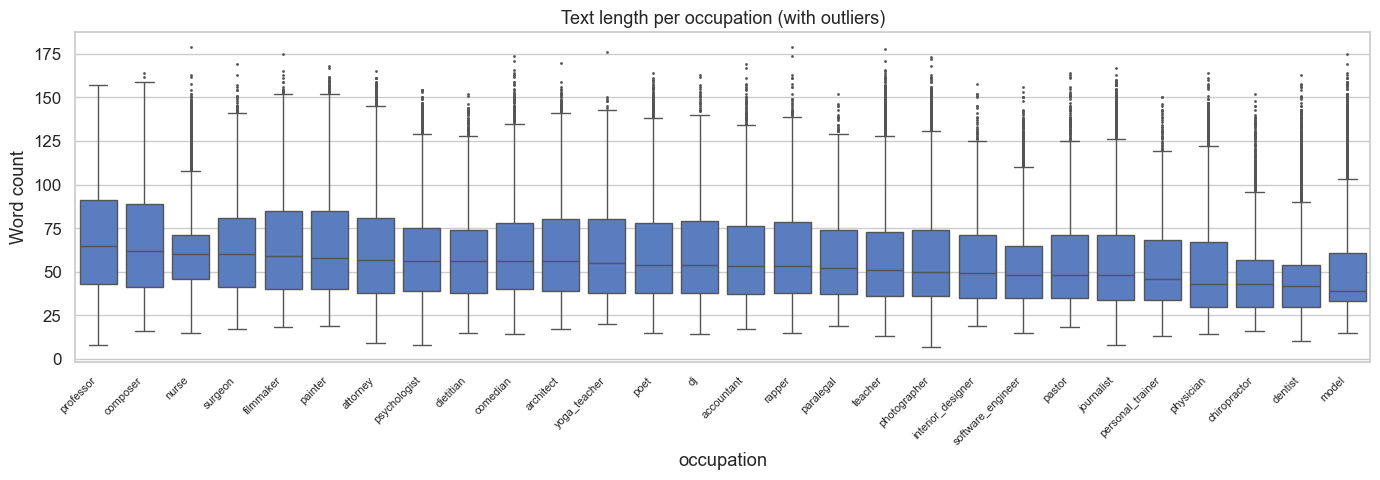

In [25]:
fig, ax = plt.subplots(figsize=(14, 5))
occ_order = (df.groupby('occupation')['word_count']
             .median().sort_values(ascending=False).index.tolist())
sns.boxplot(data=df, x='occupation', y='word_count', order=occ_order,
            ax=ax, showfliers=True, fliersize=1)
ax.set_xticks(range(len(occ_order)))
ax.set_xticklabels(occ_order, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Word count')
ax.set_title('Text length per occupation (with outliers)', fontsize=13)
plt.tight_layout()
plt.savefig('outputs/figures/fig_textlength_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** The dataset is **very clean** - no NaNs, only 809 duplicates (0.20%), and just 6 bios shorter than 10 words. Notably: **no bio exceeds 179 words** - the text is naturally compact and uniformly bounded, so outlier removal is unnecessary. The only real quality flag is **9,001 bios with URLs (2.27%)** - these may contain non-narrative boilerplate (e.g. "Visit her at www...") which spaCy will parse awkwardly; flag for sensitivity check but do not drop. HTML tags are negligible (0.11%). **No filtering needed** before the NLP pipeline.

---
## 7. Pipeline Decisions

In [26]:
MIN_N = 200
occ_counts = (df.groupby(['occupation', 'gender_label'])
              .size().unstack(fill_value=0))
occ_counts['min_n'] = occ_counts.min(axis=1)
occ_counts = occ_counts.sort_values('min_n')

thin = occ_counts[occ_counts['min_n'] < MIN_N]
safe = occ_counts[occ_counts['min_n'] >= MIN_N]

print(f'Occupations with < {MIN_N} samples in the smaller gender (caution):')
print(thin[['Female', 'Male', 'min_n']].to_string())
print()
print(f'Safe occupations (>= {MIN_N}/gender): {len(safe)} of 28')
print(safe[['Female', 'Male', 'min_n']].to_string())

Occupations with < 200 samples in the smaller gender (caution):
gender_label  Female  Male  min_n
occupation                       
rapper           136  1267    136

Safe occupations (>= 200/gender): 27 of 28
gender_label       Female   Male  min_n
occupation                             
dj                    211   1275    211
yoga_teacher         1402    257    257
paralegal            1498    267    267
interior_designer    1180    281    281
dietitian            3669    283    283
comedian              594   2215    594
pastor                606   1917    606
personal_trainer      652    778    652
chiropractor          699   1956    699
composer              917   4682    917
software_engineer    1092   5820   1092
model                6197   1294   1294
nurse               17215   1735   1735
surgeon              2014  11573   2014
accountant           2067   3566   2067
filmmaker            2305   4691   2305
architect            2393   7715   2393
poet                 3439   35

In [27]:
def scrub(text):
    return re.sub(r'\b(he|she|his|her|him|man|woman|men|women)\b',
                  '[PRONOUN]', text, flags=re.IGNORECASE)

print('=== Final Scrubbing List ===')
print()
print('CORE PRONOUNS:   he  she  his  her  him')
print('EXTENDED:        man  woman  men  women  (with \\b word boundaries)')
print('REPLACEMENT:     [PRONOUN]  (do not delete — spaCy needs valid sentence structure)')
print('FIRST NAMES:     via gender_guesser (separate step)')
print()
example = df.sample(1, random_state=7).iloc[0]
print(f'Example ({example["occupation"]} | {example["gender_label"]}):')
print(f'  Original: {example["hard_text"][:250]}')
print(f'  Scrubbed: {scrub(example["hard_text"])[:250]}')

=== Final Scrubbing List ===

CORE PRONOUNS:   he  she  his  her  him
EXTENDED:        man  woman  men  women  (with \b word boundaries)
REPLACEMENT:     [PRONOUN]  (do not delete — spaCy needs valid sentence structure)
FIRST NAMES:     via gender_guesser (separate step)

Example (professor | Female):
  Original: She teaches translation theory and consecutive and simultaneous interpreting at the masters in conference interpreting and directs the Diploma de Especialización en Traducción e Interpretación para los Servicios Comunitarios (DETISC), a postgraduate 
  Scrubbed: [PRONOUN] teaches translation theory and consecutive and simultaneous interpreting at the masters in conference interpreting and directs the Diploma de Especialización en Traducción e Interpretación para los Servicios Comunitarios (DETISC), a postgra


In [28]:
summary = pd.Series({
    'Total bios':                  len(df),
    'Occupations':                 df['occupation'].nunique(),
    'Gender balance (% Female)':   f'{df["gender_label"].eq("Female").mean()*100:.1f}%',
    'Bios with gender marker':     f'{df["has_any_marker"].mean()*100:.1f}%',
    'Bios without marker':         f'{(~df["has_any_marker"]).sum():,}',
    'Median text length (words)':  int(df['word_count'].median()),
    'Bios < 10 words':             len(df[df['word_count'] < 10]),
    'Bios > 500 words':            len(df[df['word_count'] > 500]),
    'Duplicates':                  df.duplicated('hard_text').sum(),
    'Safe occupations (>=200/g)':  len(safe),
})
print('=== EDA SUMMARY ===')
print(summary.to_string())

=== EDA SUMMARY ===
Total bios                    396189
Occupations                       28
Gender balance (% Female)      46.1%
Bios with gender marker        94.9%
Bios without marker           20,116
Median text length (words)        55
Bios < 10 words                    6
Bios > 500 words                   0
Duplicates                       809
Safe occupations (>=200/g)        27


In [29]:
# --- Final dataset preparation ---
n_raw = len(df)

df = df.drop_duplicates(subset='hard_text').reset_index(drop=True)
n_dedup = len(df)

df = df[df['occupation'] != 'rapper'].reset_index(drop=True)
n_final = len(df)

print('Cleaning pipeline:')
print(f'  Raw merged df:         {n_raw:>7,}')
print(f'  After drop_duplicates: {n_dedup:>7,}  (-{n_raw - n_dedup:,} duplicates)')
print(f'  After removing rapper: {n_final:>7,}  (-{n_dedup - n_final:,} bios)')
print()
vc = df['gender_label'].value_counts()
print(f'Final df: {n_final:,} bios | {df["occupation"].nunique()} occupations | '
      f'{vc["Male"]:,} Male ({vc["Male"]/n_final*100:.1f}%) / '
      f'{vc["Female"]:,} Female ({vc["Female"]/n_final*100:.1f}%)')

# Save as input for 02_preprocessing.ipynb
df[['hard_text', 'profession', 'gender', 'occupation', 'gender_label', 'word_count']].to_parquet(
    'outputs/df_clean.parquet', index=False
)
print('\nSaved → outputs/df_clean.parquet')

Cleaning pipeline:
  Raw merged df:         396,189
  After drop_duplicates: 395,380  (-809 duplicates)
  After removing rapper: 393,977  (-1,403 bios)

Final df: 393,977 bios | 27 occupations | 211,799 Male (53.8%) / 182,178 Female (46.2%)

Saved → outputs/df_clean.parquet


**Interpretation & Final Decisions:**

1. **Drop duplicates:** 809 duplicate bios removed (0.20%). A person overrepresented in the corpus inflates their occupation-gender cell directly -> drop before OLS.

2. **Rapper excluded from all analyses** (not just sub-analyses): 136 Female samples is below reliable estimation threshold. All downstream work uses **27 occupations**.

3. **Gender marker scrubbing:** the pronouns and titles of De-Arteaga et al. (2019), `he, she, her, his, him, hers, himself, herself, mr, mrs, ms`, with `\b` word boundaries, deleted without a placeholder. The gendered nouns `man, woman, men, women` are kept: they carry occupational meaning rather than referring to the subject. First names via spaCy NER and `gender_guesser` as a separate subsequent step. Notebook 02 carries out both steps. The cell above still prints the plan of this stage, with a `[PRONOUN]` placeholder and the gendered nouns in the list; the rule described here is the one that was run.

4. **Text length control:** `log(word_count)` in all OLS models. The M/F gap is flat at 1-2 words across all quantiles (p10 to p95) - the gap is proportional, not upper-tail driven. A single log term is sufficient; no quantile interaction needed.

5. **Bios without gender markers (~5%, n~20K):** Keep - label comes from original crawl. Run as separate robustness check.

6. **URLs in ~2.3% of bios:** Do not drop. Flag for spaCy sensitivity check after pipeline run.

7. **`start_pos` field:** Does not exist in the HuggingFace version of the dataset. The 6 short bios (<10 words) are real short bios, not truncated text.

## 8. Share of women per occupation: Bias in Bios against the BLS

Figure A1 of the thesis. The cleaned corpus is compared per occupation with the
share of women in the US labour force (`config/occupation_metadata_27.csv`, BLS
Current Population Survey, Table 11, annual averages 2025). The occupations that
Study 2 uses are marked. The printed table is Table A1 of Appendix A.

The section runs after section 7, because it reads `outputs/df_clean.parquet`.


Table for Appendix A1 (sorted by the share of women in the bios):
       occupation  n_bios  pct_women_bios  median_words in_study2  pct_women_bls_2025
               dj    1485            14.2          54.0        no                 NaN
          surgeon   13565            14.8          60.0       yes                25.9
software_engineer    6886            15.8          48.0       yes                20.3
         composer    5591            16.4          62.0        no                28.5
         comedian    2804            21.1          56.0        no                47.8
        architect   10081            23.7          56.0       yes                29.8
           pastor    2519            24.1          48.0        no                23.7
     chiropractor    2614            26.6          43.0        no                31.1
        filmmaker    6984            32.9          59.0        no                43.6
          dentist   14525            35.3          42.0       yes         

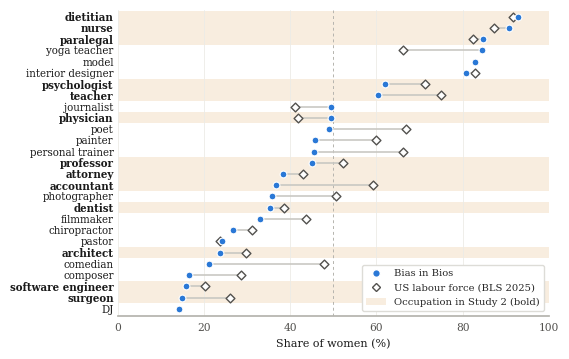

In [30]:
# -- Figure A1 of the thesis: share of women per occupation, Bias in Bios vs BLS --
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

df_fig = pd.read_parquet('outputs/df_clean.parquet')
meta = pd.read_csv('config/occupation_metadata_27.csv')

share = (df_fig.groupby('occupation')
         .agg(n_bios=('gender_label', 'size'),
              pct_women_bios=('gender_label', lambda s: (s == 'Female').mean() * 100),
              median_words=('word_count', 'median'))
         .reset_index()
         .merge(meta[['occ', 'in_study2', 'pct_women_bls_2025']],
                left_on='occupation', right_on='occ', how='left')
         .drop(columns='occ')
         .sort_values('pct_women_bios'))
assert len(share) == 27 and share['in_study2'].notna().all()

print('Table for Appendix A1 (sorted by the share of women in the bios):')
print(share.round(1).to_string(index=False))
print(f"\nrange in the bios: {share['pct_women_bios'].min():.1f}% "
      f"({share.iloc[0]['occupation']}) to {share['pct_women_bios'].max():.1f}% "
      f"({share.iloc[-1]['occupation']})")
both = share.dropna(subset=['pct_women_bls_2025'])
fewer = (both['pct_women_bios'] < both['pct_women_bls_2025']).sum()
print(f"occupations with fewer women in the bios than in the BLS data: {fewer} of {len(both)}")

INK, GREY = '#1a1a1a', '#52514e'
BIO, S2_FILL = '#2a78d6', '#f8eddf'
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(5.6, 3.5))
for i, row in enumerate(share.itertuples()):
    if row.in_study2 == 'yes':
        ax.axhspan(i - 0.5, i + 0.5, color=S2_FILL, zorder=0, lw=0)
    if pd.notna(row.pct_women_bls_2025):
        ax.plot([row.pct_women_bios, row.pct_women_bls_2025], [i, i],
                color='#c9c8c3', lw=1.2, zorder=1, solid_capstyle='round')
        ax.scatter([row.pct_women_bls_2025], [i], marker='D', s=20,
                   facecolor='white', edgecolor=GREY, lw=1.0, zorder=3)
    ax.scatter([row.pct_women_bios], [i], marker='o', s=24, color=BIO,
               edgecolor='white', lw=0.8, zorder=4)

labels = ['DJ' if o == 'dj' else o.replace('_', ' ') for o in share['occupation']]
ax.set_yticks(range(len(share)))
ax.set_yticklabels(labels, fontsize=7.4, color=INK)
for tick, s2 in zip(ax.get_yticklabels(), share['in_study2']):
    if s2 == 'yes':
        tick.set_fontweight('bold')
ax.set_ylim(-0.6, len(share) - 0.4)
ax.set_xlim(0, 100)
ax.set_xlabel('Share of women (%)', fontsize=8, color=INK)
ax.tick_params(axis='x', labelsize=7.6, colors=GREY, length=2)
ax.tick_params(axis='y', length=0, pad=3)
ax.axvline(50, color='#b5b4ae', lw=0.7, ls=(0, (3, 3)), zorder=0.5)
ax.grid(axis='x', color='#ecebe7', lw=0.6)
ax.grid(axis='y', visible=False)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#b5b4ae')
handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=BIO,
           markeredgecolor='white', markersize=5.5, label='Bias in Bios'),
    Line2D([0], [0], marker='D', color='none', markerfacecolor='white',
           markeredgecolor=GREY, markersize=4.5, label='US labour force (BLS 2025)'),
    Patch(facecolor=S2_FILL, edgecolor='none', label='Occupation in Study 2 (bold)'),
]
ax.legend(handles=handles, loc='lower right', fontsize=7.2, frameon=True,
          framealpha=1, edgecolor='#dddcd7')
plt.tight_layout(pad=0.3)
plt.savefig('outputs/figures/fig2_share_women.png', dpi=300)
plt.show()